# Cross-lingual Error Consistency and the Value of Translation

**Feeds:** RQ2 (are extraction errors consistent across languages, suggesting a
conceptual limitation, or language-specific, suggesting surface-level
processing difficulty?) and RQ4 (does extracting from the English translation
of a Portuguese article do better than extracting from the Portuguese article
itself?).

Both questions are answered from the same paired corpus, which is why they
share a notebook. The Lusa articles exist in parallel Portuguese and English
versions, the English version being a translation of the Portuguese one, and
the prompts are written in English in both conditions
(`src/meta.py`). The PT/EN contrast therefore varies exactly one thing --
the language of the input article -- which is what licenses reading the
difference as an effect of translation rather than of prompting.

**Data plumbing.** `results.csv` is aggregated per (model, template) and has no
per-document rows, so every per-document quantity below is reconstructed from
`detailed_results.csv` by counting `result` in {`tp`, `fp`, `fn`} per
(model, language, doc_id). The first analysis cell validates that
reconstruction against the published `results.csv` before anything is built on
top of it.

All analyses use the best **(template, temperature)** configuration per
(model, language) from `best_configs.json` -- the same runs notebooks 02-04
report. Since that configuration is selected on the test set, absolute F1 is
optimistic; the *differences* between languages that this notebook reports are
the quantity of interest, and both sides carry the same selection bias.

In [1]:
import sys

sys.path.insert(0, ".")

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

import _common as c

# Fixed seed: the bootstrap confidence intervals below must not move between runs.
RNG = np.random.default_rng(20250825)
N_BOOT = 10_000

In [2]:
best_configs = c.load_best_configs()
detailed = pd.concat([c.load_detailed("test", lang) for lang in c.LANGUAGE_ORDER], ignore_index=True)
best_detailed = c.filter_to_best_configs(detailed, best_configs)


def per_document_counts(df: pd.DataFrame) -> pd.DataFrame:
    """Span-level tp/fp/fn and P/R/F1 per (language, model, doc_id).

    Mirrors `src/evaluate.py::strict_metrics`, which scores on span text alone,
    so pooling these counts over documents must reproduce the micro-averaged
    figures already in results.csv -- checked in the next cell.
    """
    counts = (
        df.groupby(["language", "model", "doc_id", "result"])
        .size()
        .unstack("result")
        .reindex(columns=["tp", "fp", "fn"])
        .fillna(0.0)
        .reset_index()
    )
    denom_p = (counts["tp"] + counts["fp"]).replace(0, np.nan)
    denom_r = (counts["tp"] + counts["fn"]).replace(0, np.nan)
    counts["precision"] = (counts["tp"] / denom_p).fillna(0.0)
    counts["recall"] = (counts["tp"] / denom_r).fillna(0.0)
    denom_f1 = (counts["precision"] + counts["recall"]).replace(0, np.nan)
    counts["f1"] = (2 * counts["precision"] * counts["recall"] / denom_f1).fillna(0.0)
    return counts


per_doc = per_document_counts(best_detailed)
print(f"{len(per_doc)} (language, model, document) rows")
per_doc.head()

1737 (language, model, document) rows


result,language,model,doc_id,tp,fp,fn,precision,recall,f1
0,english,amalia,lusa_1,0.0,0.0,22.0,0.000000,0.000000,0.000000
1,english,amalia,lusa_101,0.0,0.0,23.0,0.000000,0.000000,0.000000
2,english,amalia,lusa_102,0.0,0.0,22.0,0.000000,0.000000,0.000000
3,english,amalia,lusa_103,1.0,16.0,22.0,0.058824,0.043478,0.050000
4,english,amalia,lusa_105,6.0,11.0,15.0,0.352941,0.285714,0.315789


## Validating the per-document reconstruction

Everything downstream depends on per-document counts derived from
`detailed_results.csv`. Pooling them back over documents has to reproduce the
micro-averaged precision, recall and F1 that `results.csv` already reports for
the same runs. A non-zero disagreement here would mean the detailed file and
the summary file disagree about what the run did, and no cross-lingual
comparison built on it would be trustworthy.

In [3]:
test_results = pd.concat([c.load_results("test", lang) for lang in c.LANGUAGE_ORDER], ignore_index=True)
best_test = c.filter_to_best_configs(test_results, best_configs, verbose=False)

pooled = per_doc.groupby(["language", "model"])[["tp", "fp", "fn"]].sum()
pooled["precision_rec"] = pooled["tp"] / (pooled["tp"] + pooled["fp"])
pooled["recall_rec"] = pooled["tp"] / (pooled["tp"] + pooled["fn"])
pooled["f1_rec"] = (
    2 * pooled["precision_rec"] * pooled["recall_rec"]
    / (pooled["precision_rec"] + pooled["recall_rec"])
)

check = (
    best_test.set_index(["language", "model"])[["precision", "recall", "f1"]]
    .join(pooled[["precision_rec", "recall_rec", "f1_rec"]])
)
check["max_abs_diff"] = np.maximum.reduce([
    (check["precision"] - check["precision_rec"]).abs().to_numpy(),
    (check["recall"] - check["recall_rec"]).abs().to_numpy(),
    (check["f1"] - check["f1_rec"]).abs().to_numpy(),
])

worst = check["max_abs_diff"].max()
print(f"largest disagreement over {len(check)} (language, model) pairs: {worst:.2e}")
assert worst < 1e-9, "per-document reconstruction does not reproduce results.csv"
check[["f1", "f1_rec", "max_abs_diff"]].round(6)

largest disagreement over 18 (language, model) pairs: 8.33e-17


f1    f1_rec  max_abs_diff
language   model                                             
portuguese amalia            0.169206  0.169206           0.0
           euro_llm_9b       0.260069  0.260069           0.0
           gemini            0.553134  0.553134           0.0
           gemma3_12b        0.335361  0.335361           0.0
           gemma3_4b         0.258464  0.258464           0.0
           gervasio_8b_ptpt  0.360498  0.360498           0.0
           qwen3_14b         0.327257  0.327257           0.0
           qwen3_4b          0.245785  0.245785           0.0
           qwen3_8b          0.288124  0.288124           0.0
english    amalia            0.105235  0.105235           0.0
           euro_llm_9b       0.242462  0.242462           0.0
           gemini            0.541970  0.541970           0.0
           gemma3_12b        0.369510  0.369510           0.0
           gemma3_4b         0.270296  0.270296           0.0
           gervasio_8b_ptpt  0.351032  0.351032           0.0
           qwen3_14b         0.325909  0.325909           0.0
           qwen3_4b          0.277338  0.277338           0.0
           qwen3_8b          0.295074  0.295074           0.0

## How well do the two versions actually pair?

The paired design is only as good as the pairing. The two versions were
annotated independently and in different tools (BRAT for Portuguese,
INCEpTION for English), so before comparing errors across them it is worth
checking that they annotate a comparable number of participants in the same
document. A systematic imbalance would make any language difference reported
below partly an artefact of the annotation rather than of the models.

In [4]:
gold = best_detailed[best_detailed["result"].isin(["tp", "fn"])].copy()
gold["gold_text"] = gold["token"].astype(str).str.strip().str.lower()

# The gold set is a property of the document, not of the model: every model is
# scored against the same annotations, so tp + fn is model-invariant. Asserted
# rather than assumed, since the whole pairing rests on it.
per_model_gold = gold.groupby(["language", "doc_id", "model"])["gold_text"].nunique()
spread = per_model_gold.groupby(level=["language", "doc_id"]).std().fillna(0.0)
assert spread.max() == 0, "gold participant set differs between models"

gold_counts = (
    gold.groupby(["language", "doc_id"])["gold_text"].nunique().rename("n_gold").reset_index()
    .pivot(index="doc_id", columns="language", values="n_gold")
)
SHARED_DOCS = sorted(gold_counts.dropna().index)

paired_counts = gold_counts.loc[SHARED_DOCS].copy()
paired_counts["difference"] = paired_counts["english"] - paired_counts["portuguese"]
unpaired = sorted(set(gold_counts.index) - set(SHARED_DOCS))

rho_counts = stats.spearmanr(paired_counts["portuguese"], paired_counts["english"]).statistic

print(f"documents          PT {int(gold_counts['portuguese'].notna().sum())}   "
      f"EN {int(gold_counts['english'].notna().sum())}   paired {len(SHARED_DOCS)}")
print(f"unpaired           {unpaired or 'none'}")
print(f"gold participants  PT {int(paired_counts['portuguese'].sum())}   "
      f"EN {int(paired_counts['english'].sum())}   (over the paired documents)")
print(f"per document       mean difference {paired_counts['difference'].mean():+.2f}, "
      f"mean absolute difference {paired_counts['difference'].abs().mean():.2f}")
print(f"                   identical count in {(paired_counts['difference'] == 0).mean():.1%} "
      f"of documents, Spearman rho = {rho_counts:.3f}")

paired_counts["difference"].describe().round(2)

documents          PT 97   EN 96   paired 96
unpaired           ['lusa_10']
gold participants  PT 2501   EN 2527   (over the paired documents)
per document       mean difference +0.27, mean absolute difference 0.79
                   identical count in 45.8% of documents, Spearman rho = 0.979


count    96.00
mean      0.27
std       1.17
min      -2.00
25%       0.00
50%       0.00
75%       1.00
max       4.00
Name: difference, dtype: float64

## RQ2, document level: do the same articles go wrong in both languages?

Before any summary statistic, the underlying data. Each panel below is one model
in its own best (template, temperature) configuration. The two lines trace that
model's F1 across the paired documents, one for the Portuguese original and one
for the English translation of the same article. The document order is identical
in every panel, so a given horizontal position is the same article throughout the
figure, and a trough that appears in several panels at once is one article
defeating several models.

The band between the lines is shaded by whichever version is ahead on that
document. This is what makes the figure answer two questions at once. **RQ2** is
read from the *shape*: if the two lines rise and fall together, difficulty is a
property of the article rather than of the language. **RQ4** is read from the
*shading*: if one colour dominated the band, that version would be systematically
better, and the dashed lines marking each language's mean would separate
visibly. Both readings are made formal further down, by the rank correlation and
by the translation ledger respectively.

Saved C:\Users\davib\Desktop\MSc_DataScience\thesis\gpt_struct_me\report\Figures\results\05_per_document_f1_paired_lines.pdf


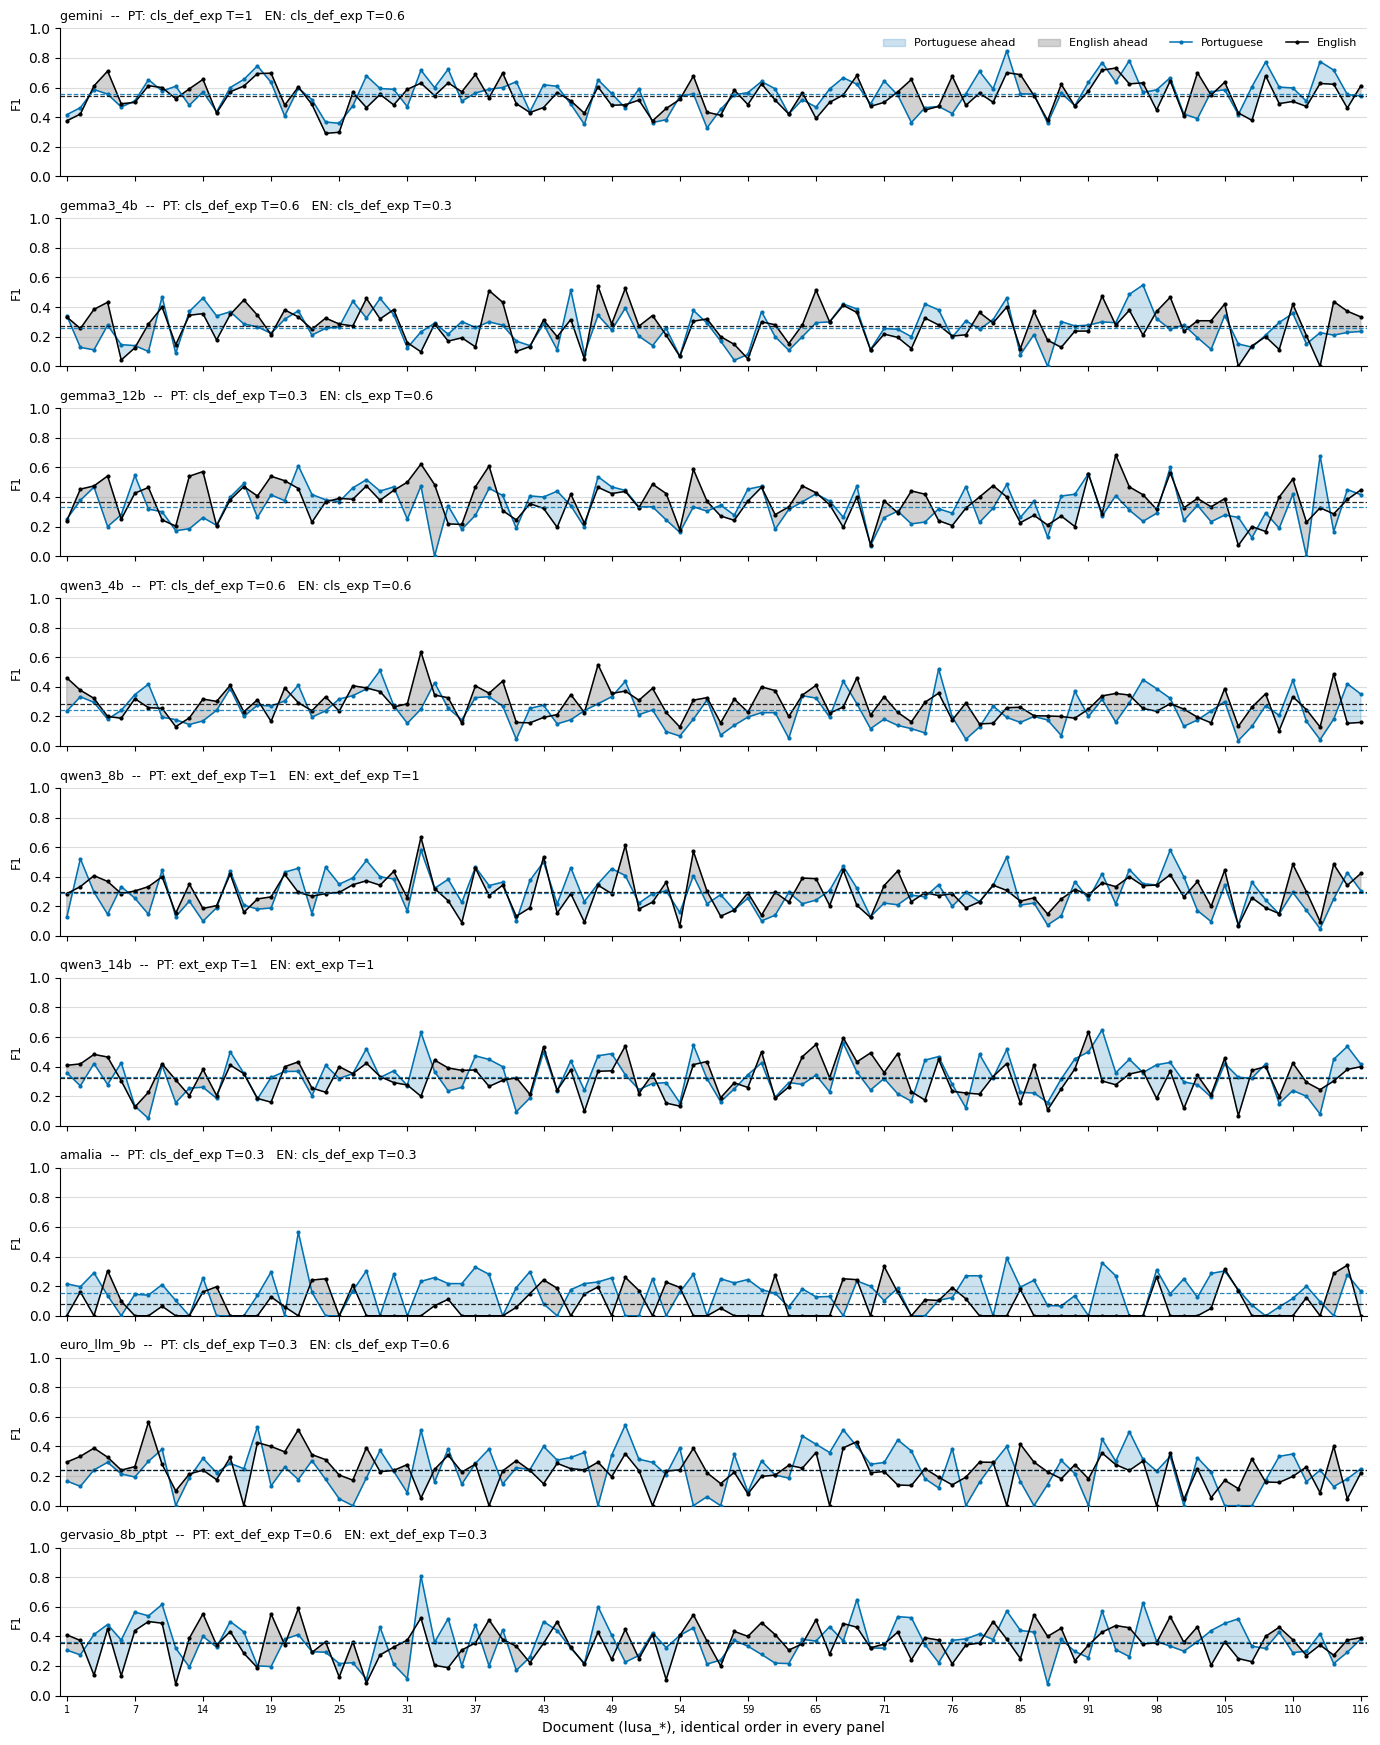

In [5]:
paired_f1 = (
    per_doc[per_doc["doc_id"].isin(SHARED_DOCS)]
    .pivot_table(index=["model", "doc_id"], columns="language", values="f1")
    .dropna(subset=c.LANGUAGE_ORDER)
    .reset_index()
)

MODELS = [m for m in c.MODEL_ORDER if m in set(paired_f1["model"])]

# Numeric order (lusa_2 before lusa_10), shared by every panel so that a given
# horizontal position is the same article throughout the figure.
DOC_ORDER = sorted(SHARED_DOCS, key=lambda d: int(str(d).rsplit("_", 1)[-1]))

x = np.arange(len(DOC_ORDER))
AHEAD_COLORS = {"portuguese": c.LANGUAGE_COLORS["portuguese"], "english": "#999999"}

fig, axes = plt.subplots(len(MODELS), 1, figsize=(14, 1.95 * len(MODELS)), sharex=True, sharey=True)
axes = np.atleast_1d(axes)

for ax, model in zip(axes, MODELS):
    sub = paired_f1[paired_f1["model"] == model].set_index("doc_id").reindex(DOC_ORDER)
    pt = sub["portuguese"].to_numpy()
    en = sub["english"].to_numpy()

    ax.fill_between(x, pt, en, where=pt >= en, interpolate=True, zorder=2,
                    color=AHEAD_COLORS["portuguese"], alpha=0.20,
                    label="Portuguese ahead" if ax is axes[0] else None)
    ax.fill_between(x, pt, en, where=en > pt, interpolate=True, zorder=2,
                    color=AHEAD_COLORS["english"], alpha=0.45,
                    label="English ahead" if ax is axes[0] else None)

    for language, series in (("portuguese", pt), ("english", en)):
        ax.plot(x, series, color=c.LANGUAGE_COLORS[language], linewidth=1.1,
                marker="o", markersize=2.0, zorder=3,
                label=language.capitalize() if ax is axes[0] else None)
        ax.axhline(np.nanmean(series), color=c.LANGUAGE_COLORS[language],
                   linewidth=0.9, linestyle="--", alpha=0.85, zorder=4)

    pt_cfg, en_cfg = (best_configs[lang][model] for lang in c.LANGUAGE_ORDER)
    ax.set_title(
        f"{model}  --  PT: {pt_cfg['base_template']} T={pt_cfg['temperature']:g}   "
        f"EN: {en_cfg['base_template']} T={en_cfg['temperature']:g}",
        fontsize=9, loc="left",
    )
    ax.set_ylim(0, 1)
    ax.set_ylabel("F1", fontsize=9)
    ax.margins(x=0.005)
    c.style_axis(ax)

axes[-1].set_xticks(x[::5], [d.replace("lusa_", "") for d in DOC_ORDER[::5]], fontsize=7)
axes[-1].set_xlabel("Document (lusa_*), identical order in every panel")
axes[0].legend(frameon=False, ncol=4, fontsize=8, loc="upper right")
c.save_fig(fig, "05_per_document_f1_paired_lines")
plt.show()

### Summarising that agreement: rank correlation

Reading the traces by eye gives an impression, not a measurement. Turning that
impression into a number calls for a correlation, and the appropriate one here is
Spearman's rank correlation rather than Pearson's, because per-document F1 is
bounded, zero-inflated and not remotely normal. Spearman discards the magnitudes
and keeps only the *ordering*: it ranks the documents from hardest to easiest
within each language and asks whether the two rankings agree.

The figure below therefore plots exactly what the statistic operates on. Each
document is placed by its **rank** under Portuguese against its **rank** under
English, rank 1 being the document the model scored lowest on. Points falling
along the diagonal mean the two versions order the documents the same way, which
is a high rho; a shapeless cloud means the orderings are unrelated, which is
rho near zero. The figure and the number are the same object, so the number is
not asking to be taken on trust.

Documents on which the model scores identically -- most often a shared zero --
are tied, and tied ranks are averaged, which is what Spearman itself does. Those
ties show up as clumps, and where a model produces many of them the ranking
carries correspondingly little information.

Note what rho does not say. It is insensitive to level: a model scoring uniformly
half as well on the translation would rank the documents identically and still
score rho = 1. Whether one language is actually better is a different question,
and it is kept separate and answered by the ledger at the end of this notebook.

Saved C:\Users\davib\Desktop\MSc_DataScience\thesis\gpt_struct_me\report\Figures\results\05_per_document_rank_agreement.pdf


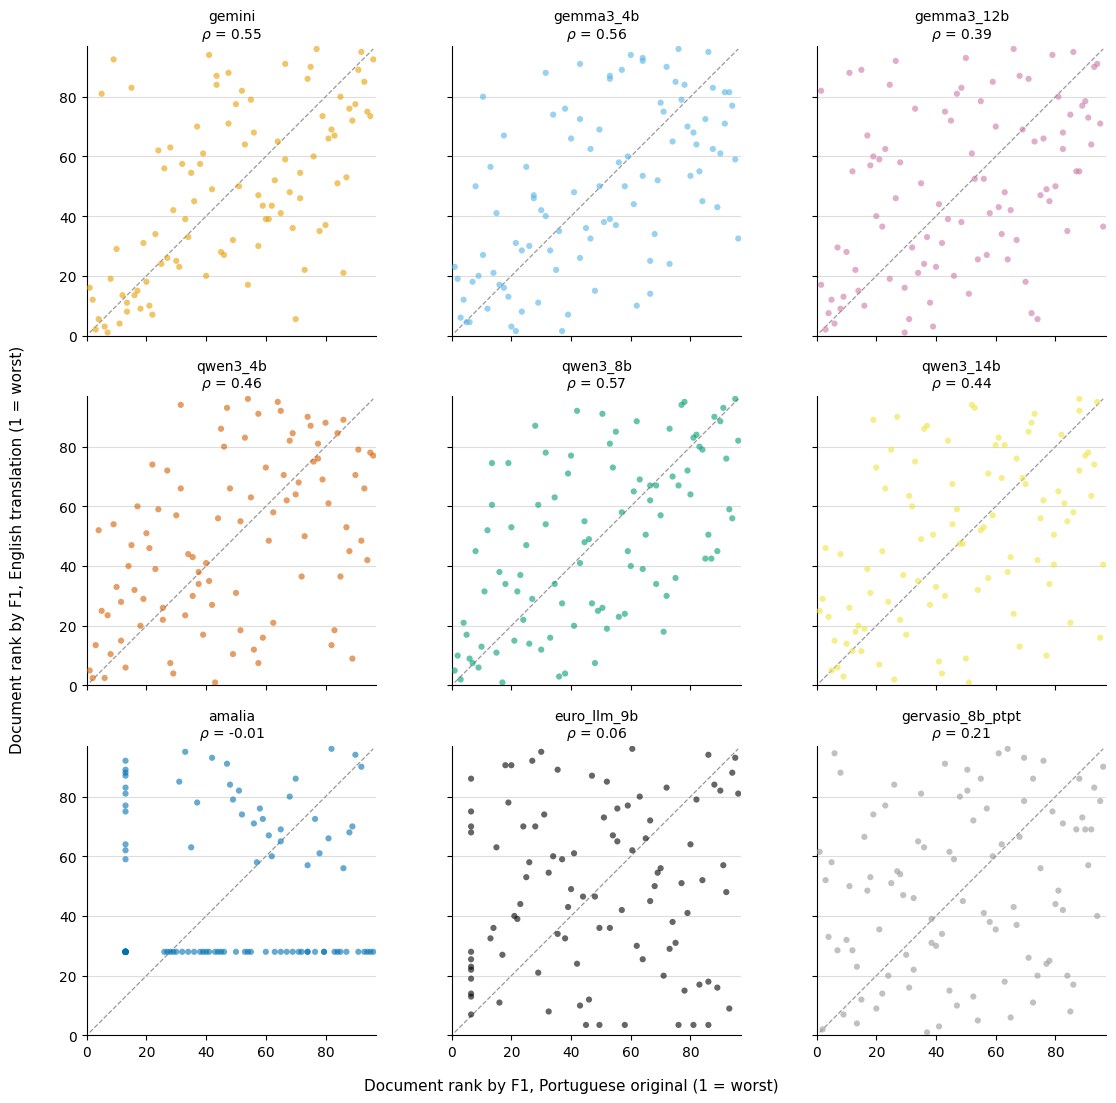

,model,spearman_rho,p_value,n_docs,pct_tied_pt,pct_tied_en
0,qwen3_8b,0.5694,0.0000,96,0.1458,0.2604
1,gemma3_4b,0.5642,0.0000,96,0.3229,0.2188
2,gemini,0.5522,0.0000,96,0.1250,0.1979
3,qwen3_4b,0.4569,0.0000,96,0.1875,0.2396
4,qwen3_14b,0.4393,0.0000,96,0.0938,0.1667
5,gemma3_12b,0.3899,0.0001,96,0.1250,0.1979
6,gervasio_8b_ptpt,0.2109,0.0392,96,0.1875,0.2396
7,euro_llm_9b,0.0633,0.5398,96,0.2812,0.2292
8,amalia,-0.0089,0.9310,96,0.3646,0.5938


In [6]:
NCOLS = 3
nrows = int(np.ceil(len(MODELS) / NCOLS))
fig, axes = plt.subplots(nrows, NCOLS, figsize=(3.9 * NCOLS, 3.7 * nrows), sharex=True, sharey=True)

rho_rows = []
for ax, model in zip(axes.ravel(), MODELS):
    sub = paired_f1[paired_f1["model"] == model]

    # Average ranks over ties -- the same convention scipy uses internally, so
    # the picture is the exact input to the coefficient reported beside it.
    rank_pt = sub["portuguese"].rank(method="average")
    rank_en = sub["english"].rank(method="average")
    rho, p_value = stats.spearmanr(sub["portuguese"], sub["english"])
    rho_rows.append({
        "model": model,
        "spearman_rho": rho,
        "p_value": p_value,
        "n_docs": len(sub),
        "pct_tied_pt": (sub["portuguese"].duplicated(keep=False)).mean(),
        "pct_tied_en": (sub["english"].duplicated(keep=False)).mean(),
    })

    n = len(sub)
    ax.plot([1, n], [1, n], color="#999999", linewidth=0.9, linestyle="--", zorder=2)
    ax.scatter(rank_pt, rank_en, s=20, alpha=0.6,
               color=c.MODEL_COLORS[model], edgecolor="none", zorder=3)
    ax.set_title(f"{model}\n" + r"$\rho$ = " + f"{rho:.2f}", fontsize=10)
    ax.set_xlim(0, n + 1)
    ax.set_ylim(0, n + 1)
    ax.set_aspect("equal", adjustable="box")
    c.style_axis(ax)

for ax in axes.ravel()[len(MODELS):]:
    ax.set_visible(False)

fig.supxlabel("Document rank by F1, Portuguese original (1 = worst)", fontsize=11)
fig.supylabel("Document rank by F1, English translation (1 = worst)", fontsize=11)
c.save_fig(fig, "05_per_document_rank_agreement")
plt.show()

rho_table = pd.DataFrame(rho_rows).sort_values("spearman_rho", ascending=False).reset_index(drop=True)
rho_table.round(4)

## RQ2, participant level: shared versus language-specific failure

The rank agreement above is measured in aggregate per document, but a document
can score the same F1 in both languages while failing on entirely different
participants. This section asks the sharper question: is a given *participant*
missed in both versions, or only in one?

Matching individual participants across the two versions by their span text is
not possible in general, since a participant's span is itself translated and
only proper names survive unchanged. The comparison is therefore made one
level up, on **(document, coarse type) cells**. For each
document and each coarse participant type, recall is computed in both
languages and the cell is labelled by whether the type was recovered in both
versions, in one only, or in neither. Location subtypes are collapsed first
via `_common.coarsen_types`, for the reason given in notebook 03.

A high *missed in both* share is the signature of a conceptual limitation: the
model fails on that kind of participant regardless of the language it is
written in. A high *Portuguese only* or *English only* share is the signature
of a language-specific one.

In [7]:
coarse = c.coarsen_types(best_detailed)

gold_cells = coarse[
    coarse["result"].isin(["tp", "fn"])
    & coarse["annt_type"].isin(c.PROMPT_CLASSES_COARSE)
    & coarse["doc_id"].isin(SHARED_DOCS)
].copy()

cell = (
    gold_cells.assign(found=lambda d: (d["result"] == "tp").astype(int))
    .groupby(["language", "model", "doc_id", "annt_type"])
    .agg(n_gold=("found", "size"), n_found=("found", "sum"))
    .reset_index()
)
cell["recall"] = cell["n_found"] / cell["n_gold"]

paired_cells = (
    cell.pivot_table(index=["model", "doc_id", "annt_type"], columns="language", values="recall")
    .dropna(subset=c.LANGUAGE_ORDER)
    .reset_index()
)

OUTCOMES = ["found in both", "Portuguese only", "English only", "missed in both"]
OUTCOME_COLORS = {
    "found in both": "#009E73",
    "Portuguese only": "#0072B2",
    "English only": "#999999",
    "missed in both": "#D55E00",
}


def label_outcome(row) -> str:
    pt_ok, en_ok = row["portuguese"] > 0, row["english"] > 0
    if pt_ok and en_ok:
        return "found in both"
    if pt_ok:
        return "Portuguese only"
    if en_ok:
        return "English only"
    return "missed in both"


paired_cells["outcome"] = paired_cells.apply(label_outcome, axis=1)

n_cells_total = len(cell.set_index(["model", "doc_id", "annt_type"]).index.unique())
print(f"paired (document, type) cells: {len(paired_cells)} "
      f"of {n_cells_total} distinct cells across both languages "
      f"({len(paired_cells) / n_cells_total:.1%} pair)")
paired_cells["outcome"].value_counts(normalize=True).round(3)

paired (document, type) cells: 4482 of 4482 distinct cells across both languages (100.0% pair)


outcome
found in both      0.505
missed in both     0.250
English only       0.129
Portuguese only    0.116
Name: proportion, dtype: float64

Saved C:\Users\davib\Desktop\MSc_DataScience\thesis\gpt_struct_me\report\Figures\results\05_shared_vs_language_specific.pdf


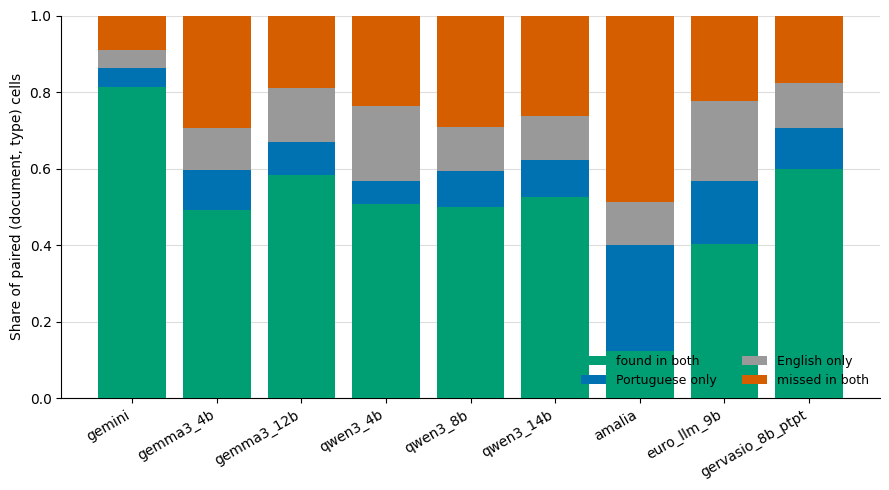

outcome,found in both,Portuguese only,English only,missed in both
model,,,,
gemini,0.813,0.050,0.046,0.090
gemma3_4b,0.492,0.104,0.110,0.293
gemma3_12b,0.582,0.086,0.141,0.191
qwen3_4b,0.506,0.062,0.195,0.237
qwen3_8b,0.500,0.094,0.114,0.291
qwen3_14b,0.526,0.096,0.114,0.263
amalia,0.122,0.277,0.112,0.488
euro_llm_9b,0.404,0.163,0.211,0.223
gervasio_8b_ptpt,0.598,0.106,0.118,0.177


In [8]:
share = (
    paired_cells.groupby(["model", "outcome"]).size().rename("n").reset_index()
    .pivot(index="model", columns="outcome", values="n")
    .reindex(columns=OUTCOMES)
    .fillna(0.0)
)
share = share.div(share.sum(axis=1), axis=0).reindex([m for m in c.MODEL_ORDER if m in share.index])

fig, ax = plt.subplots(figsize=(9, 5))
bottom = np.zeros(len(share))
for outcome in OUTCOMES:
    ax.bar(share.index, share[outcome], bottom=bottom, label=outcome,
           color=OUTCOME_COLORS[outcome], zorder=3)
    bottom += share[outcome].to_numpy()

ax.set_ylabel("Share of paired (document, type) cells")
ax.set_ylim(0, 1)
ax.legend(frameon=False, ncol=2, fontsize=9, loc="lower right")
plt.setp(ax.get_xticklabels(), rotation=30, ha="right")
c.style_axis(ax)
c.save_fig(fig, "05_shared_vs_language_specific")
plt.show()

share.round(3)

## RQ2, attribute level: is the same wrong type assigned in both languages?

Span recovery is only half of the task. Where a model recovers the same
participant in both versions, it may still type it differently in each. This
section restricts to true positives -- spans the model got right -- and
compares the type it then assigned.

Only `cls_*` templates predict a type at all, so models whose best template is
extract-only contribute nothing here and are excluded per language rather than
globally, since the best template is selected per (model, language) and can
differ between the two.

In [9]:
bc_frame = c.best_configs_frame(best_configs)
CLS_PAIRS = {
    (row.language, row.model)
    for row in bc_frame.itertuples()
    if str(row.base_template).startswith("cls")
}

excluded = sorted(set(zip(bc_frame["language"], bc_frame["model"])) - CLS_PAIRS)
print("excluded (extract-only best template, so no type is ever predicted):")
for language, model in excluded:
    print(f"  {language}/{model}")

tp_typed = coarse[
    (coarse["result"] == "tp")
    & coarse["pred_type"].notna()
    & coarse["annt_type"].notna()
    & coarse["doc_id"].isin(SHARED_DOCS)
].copy()
tp_typed = tp_typed[[(l, m) in CLS_PAIRS for l, m in zip(tp_typed["language"], tp_typed["model"])]]

type_acc = (
    tp_typed.assign(correct=lambda d: (d["pred_type"] == d["annt_type"]).astype(int))
    .groupby(["language", "model"])
    .agg(n_tp=("correct", "size"), type_accuracy=("correct", "mean"))
    .reset_index()
)

type_acc_wide = type_acc.pivot(index="model", columns="language", values="type_accuracy")
type_acc_wide["delta_en_minus_pt"] = type_acc_wide.get("english") - type_acc_wide.get("portuguese")
print()
print("Type accuracy on recovered spans (both languages must have a cls_* best template "
      "for the delta to be defined):")
type_acc_wide.round(3)

excluded (extract-only best template, so no type is ever predicted):
  english/gervasio_8b_ptpt
  english/qwen3_14b
  english/qwen3_8b
  portuguese/gervasio_8b_ptpt
  portuguese/qwen3_14b
  portuguese/qwen3_8b

Type accuracy on recovered spans (both languages must have a cls_* best template for the delta to be defined):


language,english,portuguese,delta_en_minus_pt
model,,,
amalia,0.759,0.795,-0.036
euro_llm_9b,0.697,0.766,-0.069
gemini,0.866,0.892,-0.026
gemma3_12b,0.822,0.827,-0.005
gemma3_4b,0.832,0.821,0.011
qwen3_4b,0.800,0.841,-0.041


Saved C:\Users\davib\Desktop\MSc_DataScience\thesis\gpt_struct_me\report\Figures\results\05_type_confusion_focus.pdf


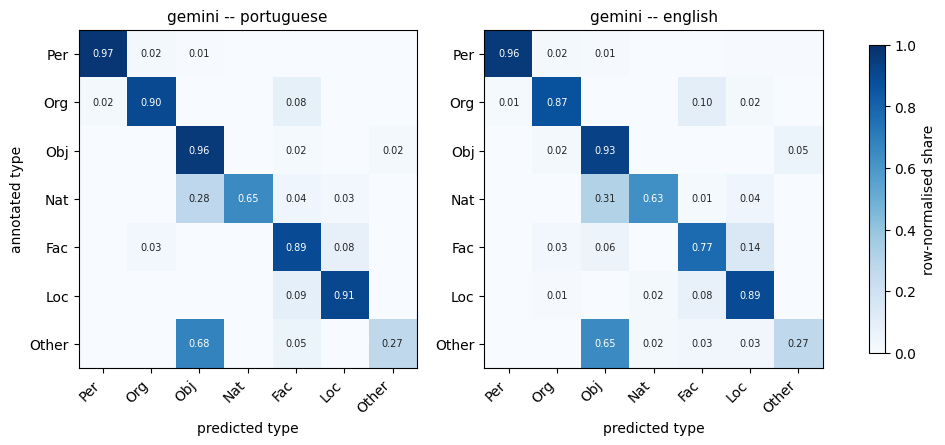

In [10]:
# Illustrative pair of confusion matrices: the strongest model, both languages.
FOCUS = "gemini"
focus_rows = tp_typed[tp_typed["model"] == FOCUS]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, language in zip(axes, c.LANGUAGE_ORDER):
    sub = focus_rows[focus_rows["language"] == language]
    matrix = (
        pd.crosstab(sub["annt_type"], sub["pred_type"], normalize="index")
        .reindex(index=c.PROMPT_CLASSES_COARSE, columns=c.PROMPT_CLASSES_COARSE)
        .fillna(0.0)
    )
    im = ax.imshow(matrix.to_numpy(), cmap=c.HEATMAP_CMAP, vmin=0, vmax=1)
    ax.set_xticks(range(len(matrix.columns)), matrix.columns, rotation=45, ha="right")
    ax.set_yticks(range(len(matrix.index)), matrix.index)
    ax.set_title(f"{FOCUS} -- {language}", fontsize=11)
    ax.set_xlabel("predicted type")
    if language == c.LANGUAGE_ORDER[0]:
        ax.set_ylabel("annotated type")
    for i in range(matrix.shape[0]):
        for j in range(matrix.shape[1]):
            value = matrix.to_numpy()[i, j]
            if value > 0.005:
                ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=7,
                        color="white" if value > 0.5 else "#222222")
fig.colorbar(im, ax=axes, shrink=0.8, label="row-normalised share")
c.save_fig(fig, "05_type_confusion_focus", tight=False)
plt.show()

## RQ4: does the translation help?

The sections above establish *whether* the two languages fail together. This
one asks whether either language is systematically better, which is precisely
RQ4: extracting from the English translation of a Portuguese article versus
extracting from the Portuguese article directly.

The ledger below collects every language delta reported across the results
chapter into one place, all signed as **English minus Portuguese**, so a
positive value means the translation helped:

- `d_f1`, `d_f1_r` -- span-level, from the best configuration of each model;
- `d_type_accuracy` -- attribute-level, from the section above;
- `d_no_answer`, `d_parse_failure` -- output-reliability counts, which are a
  failure mode distinct from getting the span wrong.

The paired test uses the per-document F1 differences over the paired
documents. Wilcoxon signed-rank is used rather than a t-test, for the same
distributional reason as before, and the confidence interval on the mean
difference is a percentile bootstrap over documents.

In [11]:
def load_failure_counts(kind: str) -> pd.DataFrame:
    """Counts of `kind` ("no_answer" / "parse_failures") per (language, model, template).

    The files list one absolute answer-file path per line, laid out as
    results/test/<language>/<model>/participants/<base_template>/<run>/<doc>.txt
    """
    rows = []
    for language in c.LANGUAGE_ORDER:
        path = c.RESULTS_DIR / "test" / language / f"{kind}.txt"
        if not path.exists():
            continue
        for line in path.read_text(encoding="utf-8", errors="replace").splitlines():
            line = line.strip()
            if not line:
                continue
            parts = Path(line.replace("\\", "/")).parts
            if "test" not in parts:
                continue
            i = parts.index("test")
            if len(parts) < i + 7:
                continue
            rows.append({
                "language": parts[i + 1],
                "model": parts[i + 2],
                "template": parts[i + 5],
                "doc_id": Path(parts[-1]).stem,
                "kind": kind,
            })
    return pd.DataFrame(rows)


failures = pd.concat([load_failure_counts(k) for k in ("no_answer", "parse_failures")], ignore_index=True)
selected_runs = {(lang, model): cfg["template"] for lang, models in best_configs.items()
                 for model, cfg in models.items()}
failures = failures[[
    selected_runs.get((l, m)) == t
    for l, m, t in zip(failures["language"], failures["model"], failures["template"])
]]

failure_counts = (
    failures.groupby(["language", "model", "kind"]).size().rename("n").reset_index()
    .pivot_table(index="model", columns=["kind", "language"], values="n")
    .fillna(0.0)
)
print(f"{len(failures)} unparseable / unanswered documents inside the selected runs")
failure_counts

47 unparseable / unanswered documents inside the selected runs


kind     no_answer            parse_failures
language   english portuguese     portuguese
model                                       
amalia        43.0        1.0            3.0

In [12]:
def delta(frame: pd.DataFrame, column: str) -> pd.Series:
    """English minus Portuguese, indexed by model."""
    wide = frame.pivot(index="model", columns="language", values=column)
    return wide.get("english") - wide.get("portuguese")


span = bc_frame[["language", "model", "f1", "f1_r"]]

ledger = pd.DataFrame({
    "d_f1": delta(span, "f1"),
    "d_f1_r": delta(span, "f1_r"),
    "d_type_accuracy": delta(type_acc, "type_accuracy"),
})

for kind in ("no_answer", "parse_failures"):
    sub = failures[failures["kind"] == kind].groupby(["language", "model"]).size().rename("n").reset_index()
    if sub.empty:
        ledger[f"d_{kind}"] = 0.0
        continue
    wide = sub.pivot(index="model", columns="language", values="n").reindex(ledger.index).fillna(0.0)
    ledger[f"d_{kind}"] = wide.get("english", 0.0) - wide.get("portuguese", 0.0)

paired_stats = []
for model in MODELS:
    sub = paired_f1[paired_f1["model"] == model]
    differences = (sub["english"] - sub["portuguese"]).to_numpy()
    if np.allclose(differences, 0):
        p_value = np.nan
    else:
        p_value = stats.wilcoxon(differences).pvalue
    boot = RNG.choice(differences, size=(N_BOOT, differences.size), replace=True).mean(axis=1)
    low, high = np.percentile(boot, [2.5, 97.5])
    paired_stats.append({
        "model": model,
        "mean_d_doc_f1": differences.mean(),
        "ci_low": low,
        "ci_high": high,
        "wilcoxon_p": p_value,
        "n_docs": differences.size,
    })

paired_stats = pd.DataFrame(paired_stats).set_index("model")
ledger = ledger.join(paired_stats).reindex([m for m in c.MODEL_ORDER if m in ledger.index])
ledger["favours"] = np.where(ledger["d_f1"] > 0, "English", np.where(ledger["d_f1"] < 0, "Portuguese", "tie"))

print("All quantities are English minus Portuguese: positive favours the translation.")
print()
print(ledger["favours"].value_counts().to_string())
ledger.round(4)

All quantities are English minus Portuguese: positive favours the translation.

favours
Portuguese    5
English       4


,d_f1,d_f1_r,d_type_accuracy,d_no_answer,d_parse_failures,mean_d_doc_f1,ci_low,ci_high,wilcoxon_p,n_docs,favours
model,,,,,,,,,,,
gemini,-0.0112,-0.0015,-0.0257,0.0,0.0,-0.0130,-0.0325,0.0062,0.0698,96,Portuguese
gemma3_4b,0.0118,0.0237,0.0107,0.0,0.0,0.0139,-0.0095,0.0369,0.2719,96,English
gemma3_12b,0.0341,0.0363,-0.0055,0.0,0.0,0.0327,0.0057,0.0609,0.0519,96,English
qwen3_4b,0.0316,0.0363,-0.0412,0.0,0.0,0.0390,0.0155,0.0628,0.0015,96,English
qwen3_8b,0.0070,0.0120,NaN,0.0,0.0,0.0064,-0.0153,0.0281,0.6498,96,English
qwen3_14b,-0.0013,0.0090,NaN,0.0,0.0,-0.0038,-0.0300,0.0216,0.9408,96,Portuguese
amalia,-0.0640,-0.1292,-0.0360,42.0,-3.0,-0.0748,-0.1064,-0.0422,0.0000,96,Portuguese
euro_llm_9b,-0.0176,0.0225,-0.0689,0.0,0.0,-0.0043,-0.0394,0.0311,0.9734,96,Portuguese
gervasio_8b_ptpt,-0.0095,0.0139,NaN,0.0,0.0,-0.0051,-0.0358,0.0253,0.7728,96,Portuguese


Saved C:\Users\davib\Desktop\MSc_DataScience\thesis\gpt_struct_me\report\Figures\results\05_translation_ledger.pdf


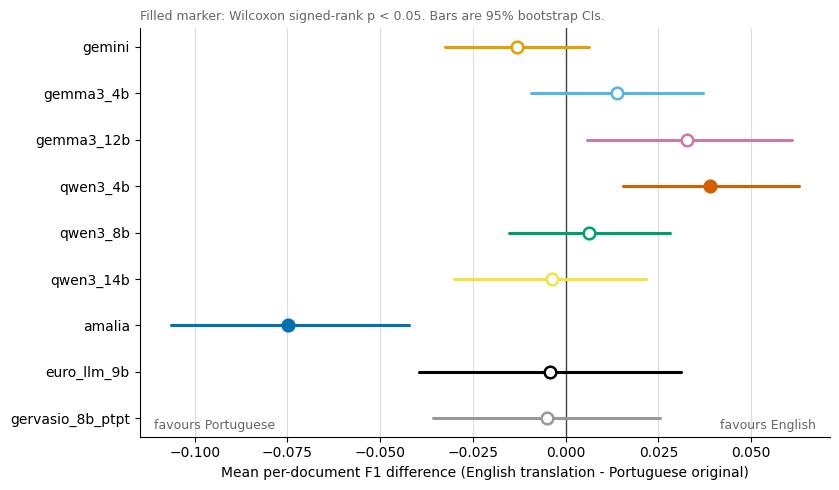

In [13]:
forest = ledger.dropna(subset=["mean_d_doc_f1"]).iloc[::-1]
y = np.arange(len(forest))

fig, ax = plt.subplots(figsize=(8.5, 5))
ax.axvline(0, color="#444444", linewidth=1.0, zorder=2)
for i, (model, row) in enumerate(forest.iterrows()):
    significant = row["wilcoxon_p"] < 0.05
    ax.plot([row["ci_low"], row["ci_high"]], [i, i],
            color=c.MODEL_COLORS[model], linewidth=2.2, zorder=3, solid_capstyle="round")
    ax.scatter([row["mean_d_doc_f1"]], [i], s=70, zorder=4,
               color=c.MODEL_COLORS[model] if significant else "white",
               edgecolor=c.MODEL_COLORS[model], linewidth=1.8)

ax.set_yticks(y, forest.index)
ax.set_xlabel("Mean per-document F1 difference (English translation - Portuguese original)")
ax.grid(axis="x", color="#DDDDDD", linewidth=0.8, zorder=0)
ax.grid(axis="y", visible=False)
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.annotate("favours Portuguese", xy=(0.02, 0.02), xycoords="axes fraction", fontsize=9, color="#666666")
ax.annotate("favours English", xy=(0.98, 0.02), xycoords="axes fraction", fontsize=9,
            color="#666666", ha="right")
ax.set_title("Filled marker: Wilcoxon signed-rank p < 0.05. Bars are 95% bootstrap CIs.",
             fontsize=9, color="#666666", loc="left")
c.save_fig(fig, "05_translation_ledger")
plt.show()

## Synthesis

- Feeds **RQ2** (the document-, participant- and attribute-level sections) and
  **RQ4** (the translation ledger).

- **Pairing.** 96 of the 97 test documents exist in both languages (`lusa_10` is
  Portuguese-only). Over those, the two annotation efforts record 2501 and 2527 gold
  participants respectively, differing by 0.79 participants per document on average,
  agreeing exactly in 45.8% of documents, and correlating at Spearman rho = 0.979.
  The pairing is therefore sound at document level. It is deliberately *not* used at
  token level: the two versions were annotated independently in different tools and a
  participant's span is itself translated, which is why the participant-level analysis
  works on (document, coarse type) cells rather than on individual participants.

- **RQ2, document level.** The paired-line figure shows the raw evidence: the two
  language traces rise and fall together across the documents, and the shaded band
  between them alternates colour rather than being dominated by either version. The
  rank correlation puts a number on it --
  per-document F1 correlates positively across the two versions for eight of the nine
  models, from rho = 0.21 (`gervasio_8b_ptpt`) to rho = 0.56 (`gemma3_4b`), every one
  significant at p < 0.05. The same articles are hard in both languages, which is
  evidence for a conceptual rather than a surface-level limitation. `amalia` is the
  sole exception (rho = -0.01, p = 0.93) and the reliability row below explains why.
  Note that rho speaks only to *ordering*: the question of whether one language scores
  systematically higher is deliberately left to the ledger.

- **RQ2, participant level.** Pooled over the 4482 paired (document, type) cells,
  50.1% are recovered in both languages and 26.4% are missed in both, against only
  12.0% missed in Portuguese alone and 11.5% missed in English alone. Shared failure is
  thus more than twice either language-specific failure, and the two language-specific
  shares are nearly symmetric -- neither language enjoys an advantage. The pattern
  holds per model, most sharply for `gemini` (77.7% found in both, 10.0% missed in
  both) and `amalia` (12.2% / 48.8%).

- **RQ2, attribute level.** Where both languages have a `cls_*` best template, type
  accuracy on recovered spans is *higher in Portuguese for every model*, by 0.006
  (`gemma3_12b`) to 0.057 (`amalia`). Typing is the one place where the translation is
  consistently worse, not better.

- **RQ4.** The ledger splits four models favouring the English translation against
  five favouring the Portuguese original. Only four per-document Wilcoxon tests reach
  p < 0.05, and they split three to one *in favour of Portuguese* (`gemini` -0.030,
  `amalia` -0.075, `euro_llm_9b` -0.029, against `qwen3_4b` +0.038); `gemma3_12b` is
  borderline at p = 0.052. Five of the nine bootstrap intervals straddle zero.
  Translating into the better-resourced language therefore produces **no systematic
  improvement**, which is the direct answer to RQ4 and is consistent with the
  conceptual reading of RQ2: a limitation that is not caused by the input language is
  not removed by changing it.

- **Reliability caveat.** `amalia` returns no answer at all for 42 English documents
  and none in Portuguese, so most of its apparent English deficit is abstention rather
  than worse extraction, and its near-zero rank correlation follows from the same
  cause. This is why the ledger carries `d_no_answer` as its own column instead of
  folding it into F1.

- **Selection caveat.** Every figure uses the best (template, temperature)
  configuration chosen on the test set, so absolute values are optimistic. The language
  *differences* are the quantity of interest here, and the same selection procedure is
  applied on both sides.